In [10]:
import numpy as np
import matplotlib.pyplot as plt
import math


In [11]:
def jacobi(A,b,x0,kmax,tol=1.0e-9):
    n=A.shape[0]
    x=np.zeros((n,1))
    y=np.copy(x0)
    k=1
    r=b-A@x0
    r0=np.copy(r)

    while np.sqrt(np.dot(r.T,r))>tol*np.sqrt(np.dot(r0.T,r0)) and (k<kmax):
            for i in range(n):
                x[i]=(b[i]-A[i,:i]@x0[:i]-\
                      A[i,i+1:]@x0[i+1:])/A[i,i]

            r=b-A@x
            x0=np.copy(x)
            y=np.hstack([y,x])
            k=k+1
    return x,k,y


In [12]:
def seidel(A,b,x0,kmax,tol=1.0e-9):
    n=A.shape[0]
    x=np.zeros((n,1))
    y=np.copy(x0)
    k=1
    r=b-A@x0
    r0=np.copy(r)

    while np.sqrt(np.dot(r.T,r))>tol*np.sqrt(np.dot(r0.T,r0)) and (k<kmax):
            for i in range(n):
                x[i]=(b[i]-A[i,:i]@x[:i]-\
                      A[i,i+1:]@x0[i+1:])/A[i,i]

            r=b-A@x
            x0=np.copy(x)
            y=np.hstack([y,x])
            k=k+1
    return x,k,y

In [13]:
def steep(Av,x,b,kmax=1e3,tol=1.0e-9):
    r = b - Av(x)
    s = r.copy()
    y = np.copy(x)
    k = 1
    for i in range(int(kmax)):
        u = Av(s)
        alpha = np.dot(s.T,r)/np.dot(s.T,u)
        x = x + alpha*r
        r = r - alpha*u
        y = np.hstack([y,x])
        k += 1
        if(math.sqrt(np.dot(r.T,r))) < tol:
            break
        s = r.copy()
    return x, k, y

In [14]:
def hilbert(n):
    C=np.zeros((n,n))
    for i in range(n):
      for j in range(n):
        C[i,j]=1.0/(i+j+1)
    return C

In [15]:
#Sistema de ecuaciones
n = 10
A = hilbert(n)
x_exacta = np.ones((n, 1))
b = A @ x_exacta
x0 = np.zeros((n, 1))
print("condicion=",np.linalg.cond(A))

condicion= 16024416987428.36


sol= [[4.28473403e+87]
 [1.00251918e+88]
 [1.40333925e+88]
 [1.70756337e+88]
 [1.94897212e+88]
 [2.14629388e+88]
 [2.31112882e+88]
 [2.45117710e+88]
 [2.57180484e+88]
 [2.67689119e+88]]
iter Jacobi= 100
velocidad de convergencia jacobi= 0.9999981315999932


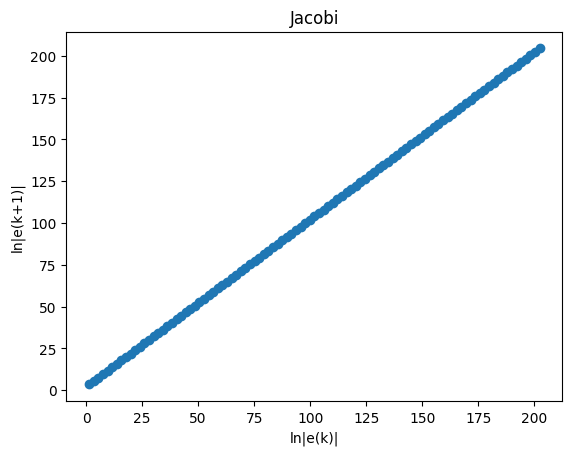

In [16]:
#Jacobi
x,k,y=jacobi(A,b,x0,1e2,tol=1.0e-9)
print("sol=",x)
print("iter Jacobi=",k)

err=np.zeros(k)
for i in range(k):
  err[i]=np.log(np.linalg.norm(y[:, i:i+1]-x_exacta))

m1, b1= np.polyfit(err[1:k-2], err[2: k-1], 1)
print("velocidad de convergencia jacobi=", m1)
plt.title("Jacobi")
plt.xlabel('ln|e(k)|')
plt.ylabel('ln|e(k+1)|')
plt.scatter(err[0:k-1], err[1: k])

sol= [[0.99677999]
 [1.02978313]
 [0.96108634]
 [0.96530966]
 [1.00852827]
 [1.03743173]
 [1.0408982 ]
 [1.0225587 ]
 [0.9889484 ]
 [0.9458877 ]]
iter seidel= 1000
error 0.10159132987060546
velocidad de convergencia seidel= 0.9838057836148522


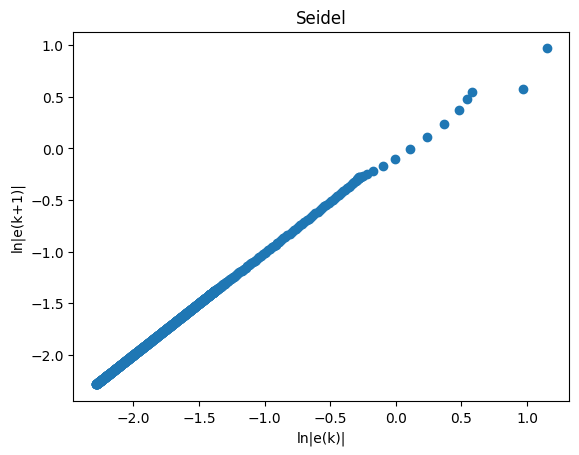

In [21]:
#Seidel
x2,k2,y2=seidel(A,b,x0,1e3,tol=1.0e-9)
print("sol=",x2)
print("iter seidel=",k2)
print("error", np.linalg.norm(x2-x_exacta))

err2=np.zeros(k2)
for i in range(k2):
  err2[i]=np.log(np.linalg.norm(y2[:, i:i+1]-x_exacta))

m2, b2= np.polyfit(err2[1:k2-2], err2[2: k2-1], 1)
print("velocidad de convergencia seidel=", m2)
plt.title("Seidel")
plt.xlabel('ln|e(k)|')
plt.ylabel('ln|e(k+1)|')
plt.scatter(err2[0:k2-1], err2[1: k2])

/tmp/ipykernel_2026/1344181926.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  if(math.sqrt(np.dot(r.T,r))) < tol:


sol= [[1.00002484]
 [0.99954072]
 [1.00167392]
 [0.99898894]
 [0.99839204]
 [0.99968092]
 [1.00124153]
 [1.00182691]
 [1.00076935]
 [0.99783138]]
iter= 100001
error 0.0041105843802080304
velocidad de convergencia descenso profundo= 0.9989665792427923


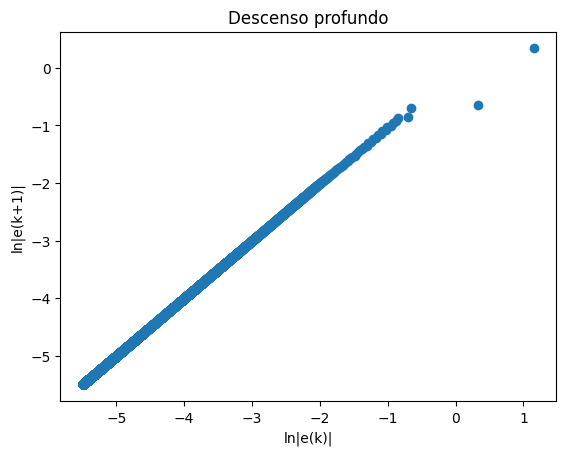

In [18]:
#Descenso profundo
def Av(x):
    return A@x
##
x3,k3,y3 = steep(Av,x0,b,tol=1.0e-9,kmax=1e5)
##

print("sol=",x3)
print("iter=",k3)
print("error", np.linalg.norm(x3-x_exacta))
err3=np.zeros(k3)
for i in range(k3):
  err3[i]=np.log(np.linalg.norm(y3[:, i:i+1]-x_exacta))

m3, b3= np.polyfit(err3[0:k3-1], err3[1: k3], 1)
print("velocidad de convergencia descenso profundo=", m3)
plt.title("Descenso profundo")
plt.xlabel('ln|e(k)|')
plt.ylabel('ln|e(k+1)|')
plt.scatter(err3[0:k3-1], err3[1: k3])